In [ ]:
!pip install astrospice

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.3/2.3 MB 36.4 MB/s eta 0:00:00


In [ ]:
!pip install sunpy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.7/3.7 MB 45.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.3/44.3 kB 3.9 MB/s eta 0:00:00


In [ ]:
!pip install sunkit_magex

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.0/50.0 kB 1.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 87.8/87.8 kB 4.3 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.9/60.9 kB 2.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 372.8/372.8 kB 13.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 37.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 191.0/191.0 kB 9.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.9/61.9 kB 3.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 379.8/379.8 kB 18.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 295.7/295.7 kB 20.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.2/9.2 MB 36.6 MB/s eta 0:00:00
  Created wheel for pims: filename=PIMS-0.7-py3-none-any.whl size=84590 sha256=9ae806413c22844e432ad15647a4e4db080b39dc849e2dcd79bacf2a51daac0d
  Stored in directory:

In [ ]:
!pip install pfsspy

In [ ]:
import os
import zipfile

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
#fixing traceback 20
import pandas as pd
import numpy as np
import datetime
import astrospice
import sunpy.coordinates
import astropy.units as u
import matplotlib.pyplot as plt

df = pd.read_csv('/content/drive/MyDrive/WI_H1_SWE_2012_2013(v2).csv')

df.columns

Index(['EPOCH_yyyy-mm-ddThh:mm:ss.sssZ', 'PROTON_BULK_SPEED_km/s',
       'XGSE_earth_radii', 'YGSE_earth_radii', 'ZGSE_earth_radii'],
      dtype='object')

In [ ]:
df['EPOCH_yyyy-mm-ddThh:mm:ss.sssZ'] = pd.to_datetime(df['EPOCH_yyyy-mm-ddThh:mm:ss.sssZ'])

# CR 2138
start_date = '2013-06-11'
end_date   = '2013-07-08'

# Filter rows within that range
mask = (df['EPOCH_yyyy-mm-ddThh:mm:ss.sssZ'] >= start_date) & (df['EPOCH_yyyy-mm-ddThh:mm:ss.sssZ'] <= end_date)
df_sel = df.loc[mask]
df_sel = df.loc[mask].copy()


output_file = 'WIND_H1_5MIN_20130611_20130708.csv'
df_sel.to_csv(output_file, index=False)

print(f"Saved {len(df_sel)} rows to {output_file}")

Saved 22453 rows to WIND_H1_5MIN_20130611_20130708.csv


In [ ]:
df_sel["PROTON_BULK_SPEED_km/s"][60:70]

,PROTON_BULK_SPEED_km/s
436236,364.414
436237,363.501
436238,359.322
436239,370.670
436240,361.437
436241,364.855
436242,363.153
436243,368.097
436244,365.929
436245,365.751


In [ ]:
import astropy.units as u
from astropy.time import Time
from astropy.coordinates import SkyCoord, CartesianRepresentation
from sunpy.coordinates import frames

df_sel['EPOCH_yyyy-mm-ddThh:mm:ss.sssZ'] = pd.to_datetime(
    df_sel['EPOCH_yyyy-mm-ddThh:mm:ss.sssZ']
)
obstimes = Time(df_sel['EPOCH_yyyy-mm-ddThh:mm:ss.sssZ'])

df_sel["XGSE_km"] = df_sel["XGSE_earth_radii"] * 6371.0
df_sel["YGSE_km"] = df_sel["YGSE_earth_radii"] * 6371.0
df_sel["ZGSE_km"] = df_sel["ZGSE_earth_radii"] * 6371.0

gse_cart = CartesianRepresentation(
    x=df_sel["XGSE_km"].values * u.km,
    y=df_sel["YGSE_km"].values * u.km,
    z=df_sel["ZGSE_km"].values * u.km,
)

sc_gse = SkyCoord(gse_cart, frame="geocentricsolarecliptic", obstime=obstimes)
sc_hci = sc_gse.transform_to(frames.HeliocentricInertial(obstime=obstimes))

# Save heliocentric Cartesian (km) and distance (AU)
df_sel["Helio_x_km"] = sc_hci.cartesian.x.to(u.km).value
df_sel["Helio_y_km"] = sc_hci.cartesian.y.to(u.km).value
df_sel["Helio_z_km"] = sc_hci.cartesian.z.to(u.km).value
df_sel["Helio_r_AU"] = sc_hci.distance.to(u.AU).value

# HCI to Carrington
sc_carr = sc_hci.transform_to(frames.HeliographicCarrington(obstime=obstimes, observer="sun"))
df_sel["Carr_lon_deg"] = sc_carr.lon.to(u.deg).value
df_sel["Carr_lat_deg"] = sc_carr.lat.to(u.deg).value
df_sel['Carr_r_km'] = sc_carr.radius.to(u.km).value
#df_sel["Carr_r_AU"]    = sc_carr.radius.to(u.AU).value

In [ ]:
solar_rad = 696000  # km
source_surface_rad = 2.5 * solar_rad  # 2.5 R_s in km
sidereal_rotation_rate_degpersec = 360 / (27.2753 * 86400)  # degrees per second

#propagation time Delta t (in seconds)
df_sel['delta_t_s'] = (df_sel['Carr_r_km'] - source_surface_rad) / df_sel['PROTON_BULK_SPEED_km/s']

#longitudinal offset D (in degrees)
df_sel['longitude_offset_D_deg'] = sidereal_rotation_rate_degpersec * df_sel['delta_t_s']

#footpoint longitude at the source surface
df_sel['footpoint_lon_deg'] = (df_sel['Carr_lon_deg'] + df_sel['longitude_offset_D_deg']) % 360

df_sel['footpoint_lat_deg'] = df_sel['Carr_lat_deg']

print("correction results:")
print(df_sel[['EPOCH_yyyy-mm-ddThh:mm:ss.sssZ', 'Carr_lon_deg', 'PROTON_BULK_SPEED_km/s',
              'delta_t_s', 'longitude_offset_D_deg', 'footpoint_lon_deg']].head(10))

df_sel.to_csv('wind_traceback20.csv', index=False)
print("\nData saved to 'wind_traceback20.csv'")

correction results:
         EPOCH_yyyy-mm-ddThh:mm:ss.sssZ  Carr_lon_deg  PROTON_BULK_SPEED_km/s  \
436176 2013-06-11 00:01:26.116000+00:00      3.089059                 383.081   
436177 2013-06-11 00:03:04.484000+00:00      3.073988                 381.085   
436178 2013-06-11 00:04:42.853000+00:00      3.058918                 379.341   
436179 2013-06-11 00:06:21.222000+00:00      3.043848                 377.436   
436180 2013-06-11 00:07:59.591000+00:00      3.028777                 376.731   
436181 2013-06-11 00:09:37.960000+00:00      3.013707                 380.874   
436182 2013-06-11 00:11:16.329000+00:00      2.998637                 383.737   
436183 2013-06-11 00:12:57.772000+00:00      2.983095                 376.922   
436184 2013-06-11 00:14:36.141000+00:00      2.968025                 379.838   
436185 2013-06-11 00:16:14.510000+00:00      2.952955                 383.103   

            delta_t_s  longitude_offset_D_deg  footpoint_lon_deg  
436176  388279.263418

In [ ]:
df_sel[5750:5780] #find longitude for (for now)start date and end date of essw

,EPOCH_yyyy-mm-ddThh:mm:ss.sssZ,PROTON_BULK_SPEED_km/s,XGSE_earth_radii,YGSE_earth_radii,ZGSE_earth_radii,XGSE_km,YGSE_km,ZGSE_km,Helio_x_km,Helio_y_km,Helio_z_km,Helio_r_AU,Carr_lon_deg,Carr_lat_deg,Carr_r_km,delta_t_s,longitude_offset_D_deg,footpoint_lon_deg,footpoint_lat_deg
441926,2013-06-17 18:46:25.826000+00:00,278.331,214.788,-94.4839,0.362527,1368414.348,-601956.9269,2309.659517,-1.478504e+08,-2.852276e+07,3.636668e+06,1.006835,273.318426,1.383517,1.506204e+08,534904.181235,81.713764,355.032190,1.383517
441927,2013-06-17 18:48:04.193000+00:00,286.223,214.787,-94.4826,0.361748,1368407.977,-601948.6446,2304.696508,-1.478499e+08,-2.852553e+07,3.637016e+06,1.006835,273.303353,1.383650,1.506204e+08,520155.384749,79.460688,352.764041,1.383650
441928,2013-06-17 18:49:42.561000+00:00,284.131,214.785,-94.4814,0.360969,1368395.235,-601940.9994,2299.733499,-1.478493e+08,-2.852831e+07,3.637365e+06,1.006836,273.288280,1.383782,1.506205e+08,523985.274692,80.045755,353.334034,1.383782
441929,2013-06-17 18:51:20.929000+00:00,286.570,214.784,-94.4801,0.360191,1368388.864,-601932.7171,2294.776861,-1.478488e+08,-2.853109e+07,3.637713e+06,1.006836,273.273206,1.383915,1.506205e+08,519525.697399,79.364495,352.637701,1.383915
441930,2013-06-17 18:52:59.297000+00:00,292.045,214.783,-94.4789,0.359412,1368382.493,-601925.0719,2289.813852,-1.478483e+08,-2.853387e+07,3.638062e+06,1.006836,273.258133,1.384047,1.506205e+08,509786.156673,77.876650,351.134783,1.384047
441931,2013-06-17 18:54:37.665000+00:00,280.404,214.782,-94.4776,0.358634,1368376.122,-601916.7896,2284.857214,-1.478478e+08,-2.853665e+07,3.638410e+06,1.006836,273.243060,1.384180,1.506205e+08,530950.047588,81.109717,354.352777,1.384180
441932,2013-06-17 18:56:16.033000+00:00,286.534,214.781,-94.4764,0.357855,1368369.751,-601909.1444,2279.894205,-1.478472e+08,-2.853943e+07,3.638759e+06,1.006836,273.227987,1.384312,1.506205e+08,519591.169509,79.374497,352.602483,1.384312
441933,2013-06-17 18:57:54.400000+00:00,281.925,214.780,-94.4752,0.357077,1368363.380,-601901.4992,2274.937567,-1.478467e+08,-2.854221e+07,3.639107e+06,1.006836,273.212914,1.384444,1.506206e+08,528085.679466,80.672147,353.885060,1.384444
441934,2013-06-17 18:59:32.768000+00:00,285.968,214.779,-94.4739,0.356298,1368357.009,-601893.2169,2269.974558,-1.478462e+08,-2.854499e+07,3.639456e+06,1.006836,273.197840,1.384577,1.506206e+08,520619.699405,79.531618,352.729459,1.384577
441935,2013-06-17 19:01:11.136000+00:00,285.049,214.778,-94.4726,0.355520,1368350.638,-601884.9346,2265.017920,-1.478457e+08,-2.854776e+07,3.639804e+06,1.006836,273.182767,1.384709,1.506206e+08,522298.247721,79.788039,352.970806,1.384709


In [ ]:
import pandas as pd
import numpy as np
from datetime import datetime, timedelta

# Constants
rotation_days = 27.2753
total_degrees = 360
time_per_degree_in_day = rotation_days / total_degrees

# Start datetime of Carrington Rotation 2138
start_datetime = datetime.fromisoformat("2013-06-11T05:21")

degrees = np.arange(total_degrees, 0, -1) #longitude decreases from 360 to 0 from start to end date

day_numbers = np.arange(0, total_degrees) * time_per_degree_in_day

timestamps = [start_datetime + timedelta(days=day) for day in day_numbers]

dfs = pd.DataFrame({
    'Degree': degrees,
    'Timestamp': timestamps
})


In [ ]:
dfs[1:20]

,Degree,Timestamp
1,359,2013-06-11 07:10:06.072
2,358,2013-06-11 08:59:12.144
3,357,2013-06-11 10:48:18.216
4,356,2013-06-11 12:37:24.288
5,355,2013-06-11 14:26:30.360
6,354,2013-06-11 16:15:36.432
7,353,2013-06-11 18:04:42.504
8,352,2013-06-11 19:53:48.576
9,351,2013-06-11 21:42:54.648
10,350,2013-06-11 23:32:00.720


In [ ]:
import pandas as pd
from datetime import timedelta
start_time=pd.to_datetime("2013-06-11 21:42:54.648")
endtime=start_time+timedelta(hours=37)
endtime

Timestamp('2013-06-13 10:42:54.648000')

In [ ]:
dfs[20:35]

,Degree,Timestamp
20,340,2013-06-12 17:43:01.440
21,339,2013-06-12 19:32:07.512
22,338,2013-06-12 21:21:13.584
23,337,2013-06-12 23:10:19.656
24,336,2013-06-13 00:59:25.728
25,335,2013-06-13 02:48:31.800
26,334,2013-06-13 04:37:37.872
27,333,2013-06-13 06:26:43.944
28,332,2013-06-13 08:15:50.016
29,331,2013-06-13 10:04:56.088


In [ ]:
# Remove bad speeds
df_sel = df_sel[
    (df_sel['PROTON_BULK_SPEED_km/s'] > 0) &
    (df_sel['PROTON_BULK_SPEED_km/s'] < 2000)
]

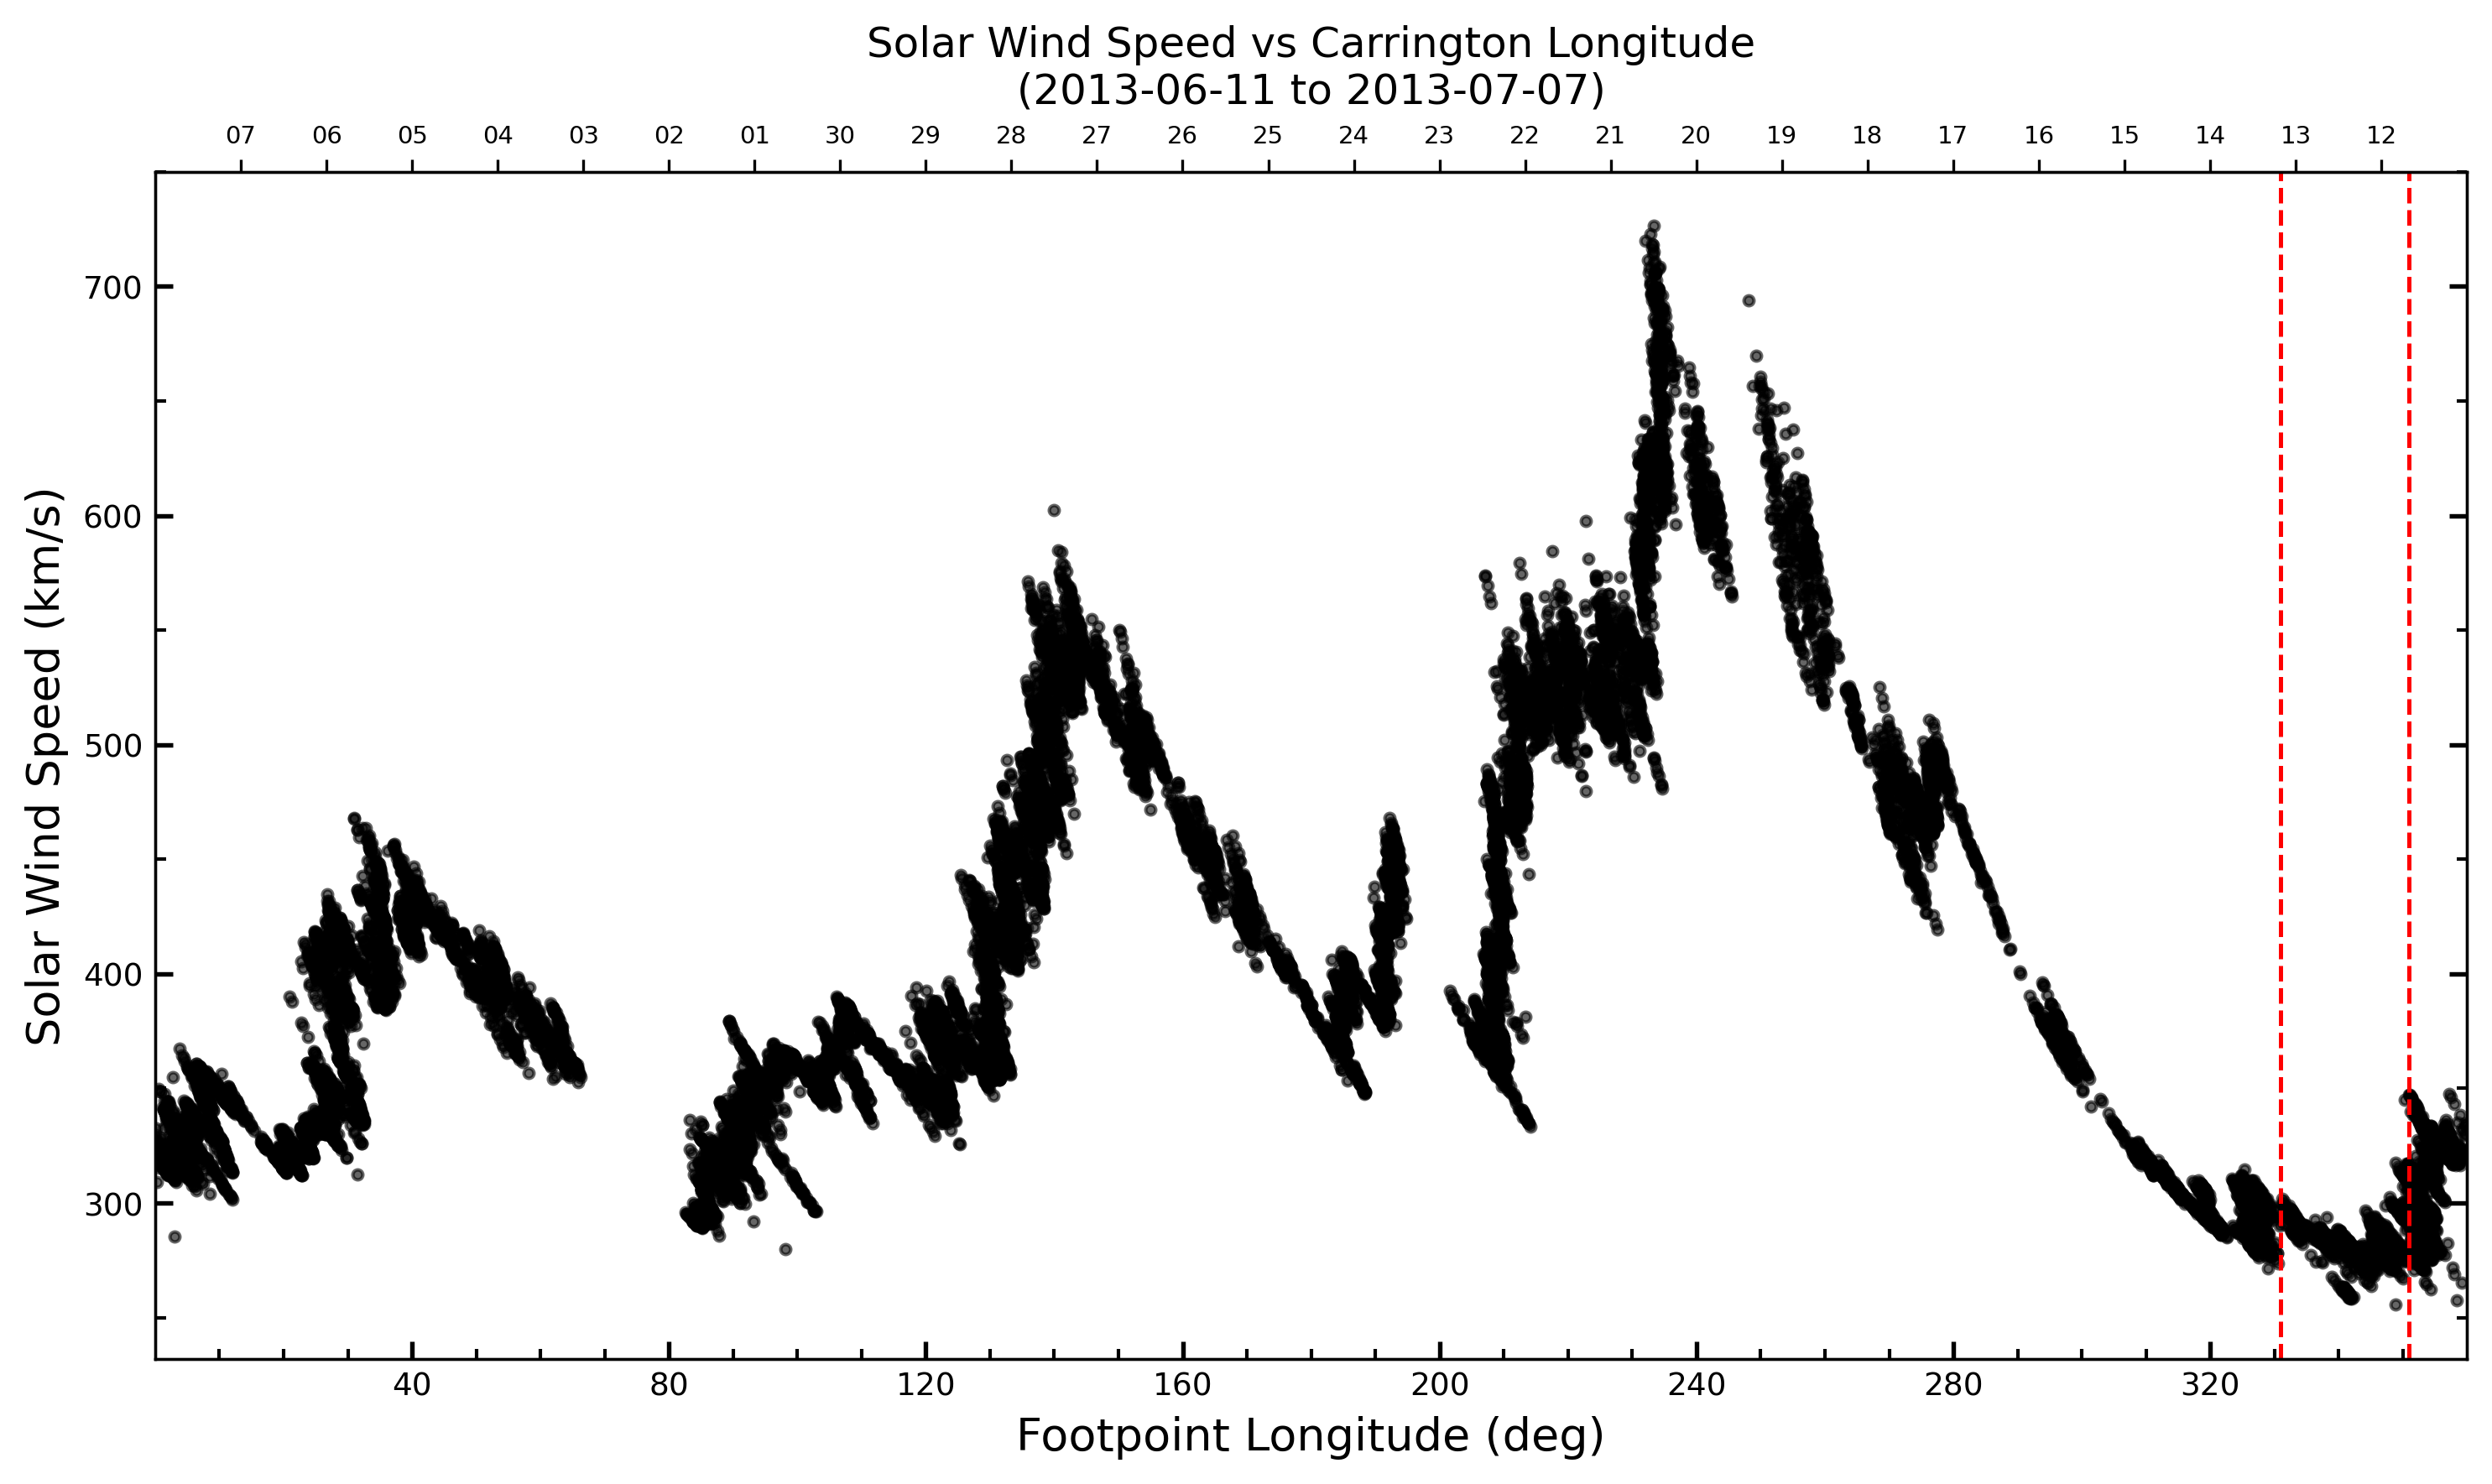

In [ ]:
start_date = df_sel['EPOCH_yyyy-mm-ddThh:mm:ss.sssZ'].min().strftime("%Y-%m-%d")
end_date = df_sel['EPOCH_yyyy-mm-ddThh:mm:ss.sssZ'].max().strftime("%Y-%m-%d")
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import AutoMinorLocator, MaxNLocator

# Ensure datetime format
df_sel['EPOCH_yyyy-mm-ddThh:mm:ss.sssZ'] = pd.to_datetime(
    df_sel['EPOCH_yyyy-mm-ddThh:mm:ss.sssZ']
)

fig, ax = plt.subplots(figsize=(10, 6), dpi=300)


ax.scatter(df_sel['footpoint_lon_deg'],
           df_sel['PROTON_BULK_SPEED_km/s'],
           s=8, alpha=0.6, color='k', label="WIND data")

ax.set_xlabel("Footpoint Longitude (deg)", fontsize=13)
ax.set_ylabel("Solar Wind Speed (km/s)", fontsize=13)
ax.minorticks_on()
ax.yaxis.set_minor_locator(AutoMinorLocator(2))
ax.tick_params(axis='both', which='major', direction='in', length=5, width=1.3, labelsize=9)
ax.tick_params(axis='both', which='minor', direction='in', length=3, width=1)
ax.xaxis.set_ticks_position('bottom')
ax.yaxis.set_ticks_position('both')

#ax.axhline(y=300, color='red', linestyle='--', linewidth=1.5, alpha=0.8, label='300 km/s threshold')
ax.axvline(x=351, color='r', linestyle='--', lw=1.2, label="Longitude range")
ax.axvline(x=331, color='r', linestyle='--', lw=1.2)

ax.xaxis.set_major_locator(MaxNLocator(10))
ax.set_xlim(min(df_sel['footpoint_lon_deg']),
            max(df_sel['footpoint_lon_deg']))

ax_top = ax.twiny()
formatter = mdates.DateFormatter('%d')   # show only day numbers
ax_top.xaxis.set_major_locator(mdates.DayLocator(interval=1))
ax_top.xaxis.set_major_formatter(formatter)


min_time = df_sel['EPOCH_yyyy-mm-ddThh:mm:ss.sssZ'].min()
max_time = df_sel['EPOCH_yyyy-mm-ddThh:mm:ss.sssZ'].max()
ax_top.set_xlim(max_time, min_time)   # reverse

plt.setp(ax_top.get_xticklabels(), rotation=0, ha='center', fontsize=7)

plt.title(f"Solar Wind Speed vs Carrington Longitude\n({min_time.date()} to {max_time.date()})")
plt.tight_layout()
plt.show()

In [ ]:
pip install mpl-animators>=1.2.0 reproject>=0.12.0

In [ ]:
import os
import matplotlib.pyplot as plt
import numpy as np

import astropy.units as u
from astropy.coordinates import SkyCoord

import sunpy.map
import sunkit_magex.pfss
import sunkit_magex.pfss.tracing as tracing

In [ ]:
filenm ='/content/drive/MyDrive/hmi.synoptic_mr_720s.2138.synopMr.fits'
hmi_map = sunpy.map.Map(filenm)
#print(hmi_map.meta)

In [ ]:
import pfsspy
import pfsspy.utils
pfsspy.utils.fix_hmi_meta(hmi_map)
# Specify data directories and data range
nrho = 35
rss =2.5
# Ensure the map is in cylindrical equal-area (CEA) projection required by pfsspy:contentReference[oaicite:1]{index=1}.
if not pfsspy.utils.is_cea_map(hmi_map):
    hmi_map = pfsspy.utils.car_to_cea(hmi_map)  # reproject Carrington->CEA:contentReference[oaicite:2]{index=2}

# Optionally downsample the HMI map to speed up PFSS computation (e.g., to 360x180 pixels):contentReference[oaicite:3]{index=3}.
hmi_map = hmi_map.resample([360, 180] * u.pix)
pfss_in =pfsspy.Input(hmi_map, nrho, rss)
pfss_out= pfsspy.pfss(pfss_in)

ValueError: At least one value in the input is NaN or non-finite. The input must consist solely of finite values.

In [ ]:
import numpy as np
import astropy.units as u
import pfsspy
import pfsspy.utils

# --- Fix HMI metadata ---
pfsspy.utils.fix_hmi_meta(hmi_map)

# --- PFSS parameters ---
nrho = 35
rss = 2.5

# --- Ensure CEA projection ---
if not pfsspy.utils.is_cea_map(hmi_map):
    hmi_map = pfsspy.utils.car_to_cea(hmi_map)  # reproject Carrington → CEA

# --- Downsample to speed up PFSS computation ---
hmi_map = hmi_map.resample([360, 180] * u.pix)

# --- FIX NaN / non-finite values ---
data = hmi_map.data
data = np.nan_to_num(data, nan=0.0, posinf=0.0, neginf=0.0)  # replace all bad values with 0
hmi_map = hmi_map._new_instance(data, hmi_map.meta, hmi_map.plot_settings)

# --- Check for any remaining invalid values (optional sanity check) ---
#print("Any NaNs left?", np.isnan(hmi_map.data).any())
#print("Any Infs left?", np.isinf(hmi_map.data).any())

# --- Run PFSS computation ---
pfss_in = pfsspy.Input(hmi_map, nrho, rss)
pfss_out = pfsspy.pfss(pfss_in)


/usr/local/lib/python3.12/dist-packages/pfsspy/output.py:95: UserWarning: Could not parse unit string "Mx/cm^2" as a valid FITS unit.
See https://fits.gsfc.nasa.gov/fits_standard.html for the FITS unit standards.
  warnings.warn(f'Could not parse unit string "{unit_str}" as a valid FITS unit.\n'
/usr/local/lib/python3.12/dist-packages/pfsspy/output.py:95: UserWarning: Could not parse unit string "Mx/cm^2" as a valid FITS unit.
See https://fits.gsfc.nasa.gov/fits_standard.html for the FITS unit standards.
  warnings.warn(f'Could not parse unit string "{unit_str}" as a valid FITS unit.\n'
/usr/local/lib/python3.12/dist-packages/pfsspy/output.py:95: UserWarning: Could not parse unit string "Mx/cm^2" as a valid FITS unit.
See https://fits.gsfc.nasa.gov/fits_standard.html for the FITS unit standards.
  warnings.warn(f'Could not parse unit string "{unit_str}" as a valid FITS unit.\n'
/usr/local/lib/python3.12/dist-packages/pfsspy/output.py:95: UserWarning: Could not parse unit string "Mx/cm^

INFO: Missing metadata for solar radius: assuming the standard radius of the photosphere. [sunpy.map.mapbase]
INFO: Missing metadata for solar radius: assuming the standard radius of the photosphere. [sunpy.map.mapbase]
INFO: Missing metadata for solar radius: assuming the standard radius of the photosphere. [sunpy.map.mapbase]
INFO: Missing metadata for solar radius: assuming the standard radius of the photosphere. [sunpy.map.mapbase]


/usr/local/lib/python3.12/dist-packages/pfsspy/output.py:95: UserWarning: Could not parse unit string "Mx/cm^2" as a valid FITS unit.
See https://fits.gsfc.nasa.gov/fits_standard.html for the FITS unit standards.
  warnings.warn(f'Could not parse unit string "{unit_str}" as a valid FITS unit.\n'
/usr/local/lib/python3.12/dist-packages/pfsspy/output.py:95: UserWarning: Could not parse unit string "Mx/cm^2" as a valid FITS unit.
See https://fits.gsfc.nasa.gov/fits_standard.html for the FITS unit standards.
  warnings.warn(f'Could not parse unit string "{unit_str}" as a valid FITS unit.\n'
/usr/local/lib/python3.12/dist-packages/pfsspy/output.py:95: UserWarning: Could not parse unit string "Mx/cm^2" as a valid FITS unit.
See https://fits.gsfc.nasa.gov/fits_standard.html for the FITS unit standards.
  warnings.warn(f'Could not parse unit string "{unit_str}" as a valid FITS unit.\n'
/usr/local/lib/python3.12/dist-packages/pfsspy/output.py:95: UserWarning: Could not parse unit string "Mx/cm^

Text(0.5, 1.0, 'carr 2138 Source surface magnetic field at 2.5 Rs')

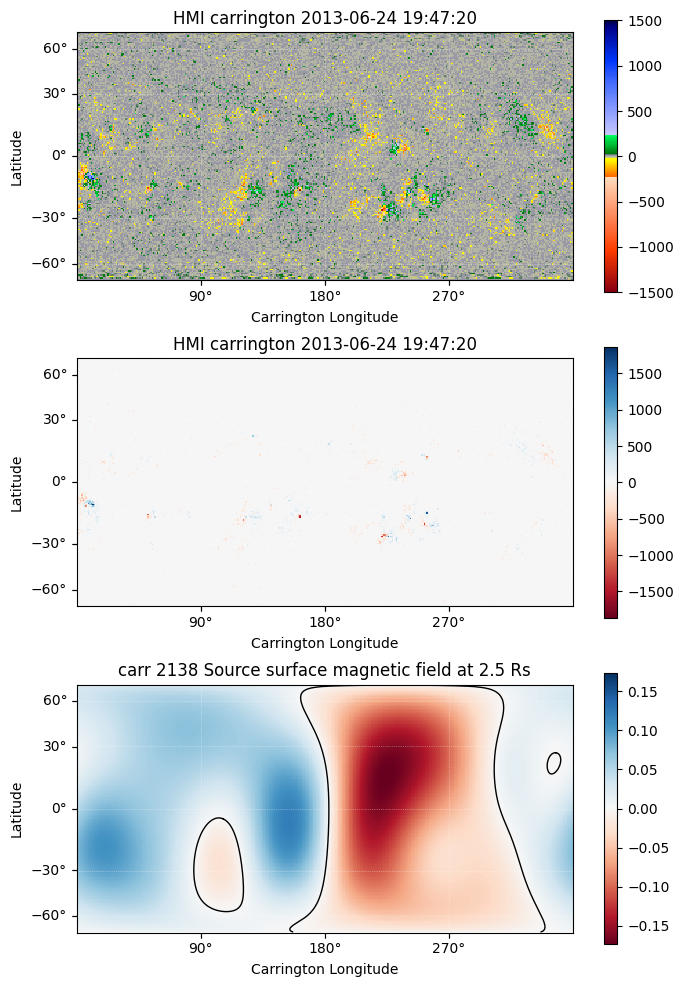

In [ ]:
m=pfss_in.map
ss_br=pfss_out.source_surface_br


fig=plt.figure(figsize=(8,12))
ax=fig.add_subplot(3,1,1,projection=hmi_map)
hmi_map.plot()
plt.colorbar()
ax=fig.add_subplot(3,1,2,projection=m)
m.plot_settings['norm'].vmin = None
m.plot_settings['norm'].vmax = None
ax.set_title('Input HMI magnetogram')
m.plot(axes=ax)
plt.colorbar()
ax=fig.add_subplot(3,1,3,projection=ss_br)
ss_br.plot()
# plot the polarity inversion line
#ax.plot_coord(pfss_out.source_surface_pils[0])
for pil in pfss_out.source_surface_pils:
    ax.plot_coord(pil, color='k', linewidth=1)
plt.colorbar()
ax.set_title("carr "+str(2138)+" Source surface magnetic field at "+str(rss)+" Rs")

/usr/local/lib/python3.12/dist-packages/pfsspy/output.py:95: UserWarning: Could not parse unit string "Mx/cm^2" as a valid FITS unit.
See https://fits.gsfc.nasa.gov/fits_standard.html for the FITS unit standards.
  warnings.warn(f'Could not parse unit string "{unit_str}" as a valid FITS unit.\n'
/usr/local/lib/python3.12/dist-packages/pfsspy/output.py:95: UserWarning: Could not parse unit string "Mx/cm^2" as a valid FITS unit.
See https://fits.gsfc.nasa.gov/fits_standard.html for the FITS unit standards.
  warnings.warn(f'Could not parse unit string "{unit_str}" as a valid FITS unit.\n'
/usr/local/lib/python3.12/dist-packages/pfsspy/output.py:95: UserWarning: Could not parse unit string "Mx/cm^2" as a valid FITS unit.
See https://fits.gsfc.nasa.gov/fits_standard.html for the FITS unit standards.
  warnings.warn(f'Could not parse unit string "{unit_str}" as a valid FITS unit.\n'
/usr/local/lib/python3.12/dist-packages/pfsspy/output.py:95: UserWarning: Could not parse unit string "Mx/cm^

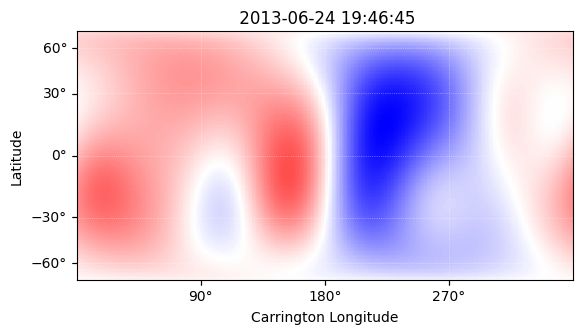

In [ ]:
pfss_out.source_surface_br.plot(cmap='bwr')

In [ ]:
# Define function which does the field line tracing
def pfss2flines(pfsspy_output, # pfsspy output object
                nth=18,nph=36, # number of tracing grid points
                rect=[-90,90,0,360], #sub-region of sun to trace (default is whole sun)
                trace_from_SS=False, # if False : start trace from photosphere,
                                     #if True, start tracing from source surface
                skycoord_in=None, # Use custom set of starting grid poitns
                max_steps = 1000 # max steps tracer should take before giving up
                ) :

    # Tracing if grid
    if skycoord_in is None  :
        [latmin,latmax,lonmin,lonmax]=rect
        lons,lats = np.meshgrid(np.linspace(lonmin,lonmax,nph),
                                np.linspace(latmin,latmax,nth)
                                )
        if not trace_from_SS : alt = 1.0*u.R_sun # Trace up from photosphere
        else : alt = pfsspy_output.grid.rss*u.R_sun  # Trace down from ss
        alt = [alt]*len(lons.ravel())
        seeds = astropy.coordinates.SkyCoord(lons.ravel()*u.deg,
                               lats.ravel()*u.deg,
                               alt,
                               frame = pfsspy_output.coordinate_frame)

    # Tracing if custom set of points
    else :
        skycoord_in.representation_type = "spherical"
        seeds = astropy.coordinates.SkyCoord(skycoord_in.lon,
                               skycoord_in.lat,
                               skycoord_in.radius,
                               frame = pfsspy_output.coordinate_frame)

    return pfsspy_output.trace(pfsspy.tracing.FortranTracer(max_steps=max_steps),seeds)

In [ ]:
# from astropy.coordinates import SkyCoord
import astropy.coordinates
# flines_highres = pfss2flines(pfss_out,nth=180,nph=360,rect=[-89.5,89.5,0.5,359.5])
flines_highres = pfss2flines(pfss_out,nth=181,nph=361)

/usr/local/lib/python3.12/dist-packages/pfsspy/output.py:95: UserWarning: Could not parse unit string "Mx/cm^2" as a valid FITS unit.
See https://fits.gsfc.nasa.gov/fits_standard.html for the FITS unit standards.
  warnings.warn(f'Could not parse unit string "{unit_str}" as a valid FITS unit.\n'
/usr/local/lib/python3.12/dist-packages/pfsspy/tracing.py:180: UserWarning: At least one field line ran out of steps during tracing.
You should probably increase max_steps (currently set to 1000) and try again.
  warnings.warn(


In [ ]:
topologies = flines_highres.polarities.reshape([181,361])

Text(0.5, 1.0, 'Coronal Hole Map Rss=2.5Rs')

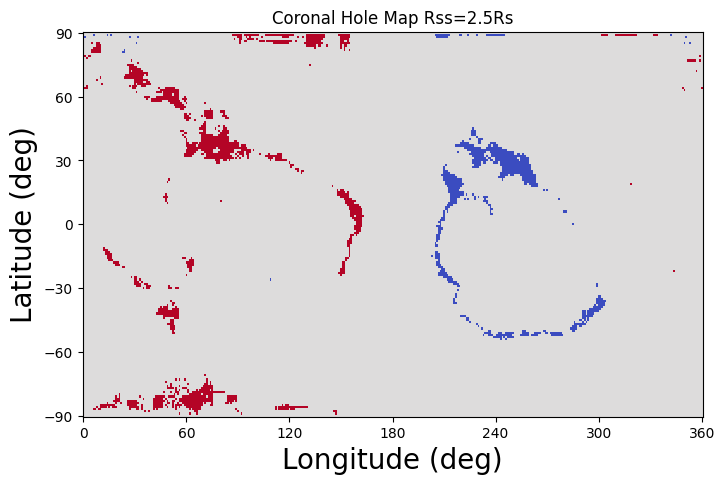

In [ ]:
lons = np.linspace(0,360,361)
lats = np.linspace(-90,90,181)
fig,ax = plt.subplots(figsize=(8,5))
ax.pcolormesh(lons,lats,topologies,cmap="coolwarm")
ax.set_xlabel("Longitude (deg)",fontsize=20)
ax.set_ylabel("Latitude (deg)",fontsize=20)
ax.set_xticks(np.linspace(0,360,7))
ax.set_yticks(np.linspace(-90,90,7))
ax.set_title(f"Coronal Hole Map Rss=2.5Rs")

In [ ]:
def source_surface_seeds(n_lon=92, n_lat=41, obstime=None):
    lon = np.linspace(0, 360, n_lon, endpoint=False)
    lat = np.arcsin(np.linspace(-0.5, 0.5, n_lat))
    lon_grid, lat_grid = np.meshgrid(lon, lat,indexing='ij')
    r = np.full_like(lat_grid, 2.5)
    return SkyCoord(
        lon_grid.flatten() * u.deg,
        lat_grid.flatten() * u.deg,
        r.flatten() * u.R_sun,
        frame='heliographic_carrington',
        obstime=obstime,
        observer='sun'
    )

tracer =pfsspy.tracing.FortranTracer(max_steps=8000,step_size=0.1)
seeds_all = source_surface_seeds(n_lon=92, n_lat=41, obstime=hmi_map.date)
flines = tracer.trace(seeds_all, pfss_out)

/usr/local/lib/python3.12/dist-packages/pfsspy/output.py:95: UserWarning: Could not parse unit string "Mx/cm^2" as a valid FITS unit.
See https://fits.gsfc.nasa.gov/fits_standard.html for the FITS unit standards.
  warnings.warn(f'Could not parse unit string "{unit_str}" as a valid FITS unit.\n'
/usr/local/lib/python3.12/dist-packages/pfsspy/output.py:95: UserWarning: Could not parse unit string "Mx/cm^2" as a valid FITS unit.
See https://fits.gsfc.nasa.gov/fits_standard.html for the FITS unit standards.
  warnings.warn(f'Could not parse unit string "{unit_str}" as a valid FITS unit.\n'
/usr/local/lib/python3.12/dist-packages/pfsspy/output.py:95: UserWarning: Could not parse unit string "Mx/cm^2" as a valid FITS unit.
See https://fits.gsfc.nasa.gov/fits_standard.html for the FITS unit standards.
  warnings.warn(f'Could not parse unit string "{unit_str}" as a valid FITS unit.\n'
/usr/local/lib/python3.12/dist-packages/pfsspy/output.py:95: UserWarning: Could not parse unit string "Mx/cm^

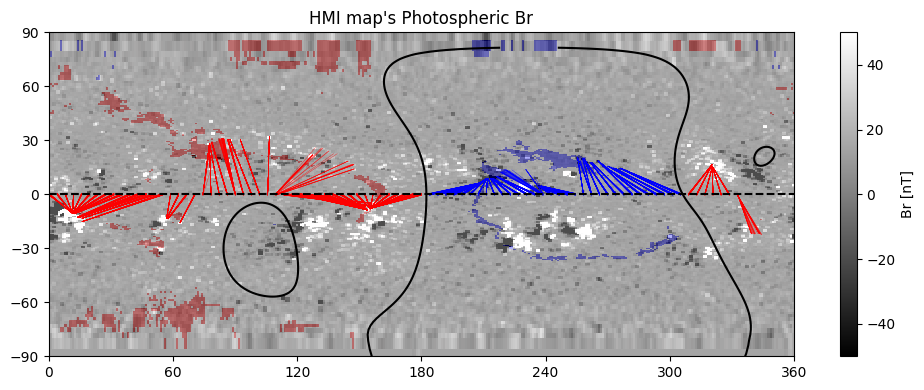

In [ ]:
from datetime import datetime, timedelta
import numpy as np
import matplotlib.pyplot as plt
import astropy.units as u

# Get longitude and latitude from PFSS output
lon = np.degrees(pfss_out.grid.pg)
lat = np.degrees(np.arcsin(pfss_out.grid.sg))
lon2, lat2 = np.meshgrid(lon, lat)

# Create the figure
fig, axes = plt.subplots(figsize=(10, 4))
axes.set_title("HMI map's Photospheric Br")

# Plot photospheric Br
c = axes.pcolor(
    lon, lat, pfss_out.bg[:, :, 0, 2].T,
    cmap='gray', norm=None,
    vmin=-50, vmax=50, shading='nearest'
)

# Plot Br=0 contour (neutral line / HCS)
axes.contour(
    lon[:-1], lat[:-1], pfss_out.source_surface_br.data,
    levels=[0], colors='k', linewidths=1.5
)

# Add colorbar
plt.colorbar(c, ax=axes, label="Br [nT]", orientation='vertical')

# Overlay topology map
axes.pcolormesh(lon2, lat2, topologies, cmap="bwr", alpha=0.3)

#  Polarity color mapping
color_dict = {-1: 'blue', 0: 'black', 1: 'red'}

# Plot magnetic field lines
for fline in flines:
    coords = fline.coords
    if len(coords.lon) == 0 or len(coords.lat) == 0:
        continue  # skip empty field lines

    # Convert coordinates
    lon_vals = coords.lon.to(u.deg).value % 360
    lat_vals = coords.lat.to(u.deg).value

    # Get polarity
    polarity = getattr(fline, "polarity", 0)
    color = color_dict.get(polarity, 'black')

    # Avoid wrap-around issue
    if np.abs(lon_vals[0] - lon_vals[-1]) < 200:
        axes.plot(
    [lon_vals[0], lon_vals[-1]],
    [lat_vals[0], lat_vals[-1]],
    color=color, lw=0.3, alpha=0.8
)

# Add equator line and axes formatting
plt.axhline(y=0, color='k', linestyle='--')
axes.set_xticks(np.linspace(0, 360, 7))
axes.set_yticks(np.linspace(-90, 90, 7))
axes.set_xlim([0, 360])
axes.set_ylim([-90, 90])

plt.tight_layout()
plt.show()

/usr/local/lib/python3.12/dist-packages/pfsspy/output.py:95: UserWarning: Could not parse unit string "Mx/cm^2" as a valid FITS unit.
See https://fits.gsfc.nasa.gov/fits_standard.html for the FITS unit standards.
  warnings.warn(f'Could not parse unit string "{unit_str}" as a valid FITS unit.\n'
/usr/local/lib/python3.12/dist-packages/pfsspy/output.py:95: UserWarning: Could not parse unit string "Mx/cm^2" as a valid FITS unit.
See https://fits.gsfc.nasa.gov/fits_standard.html for the FITS unit standards.
  warnings.warn(f'Could not parse unit string "{unit_str}" as a valid FITS unit.\n'
/usr/local/lib/python3.12/dist-packages/pfsspy/output.py:95: UserWarning: Could not parse unit string "Mx/cm^2" as a valid FITS unit.
See https://fits.gsfc.nasa.gov/fits_standard.html for the FITS unit standards.
  warnings.warn(f'Could not parse unit string "{unit_str}" as a valid FITS unit.\n'
/usr/local/lib/python3.12/dist-packages/pfsspy/output.py:95: UserWarning: Could not parse unit string "Mx/cm^

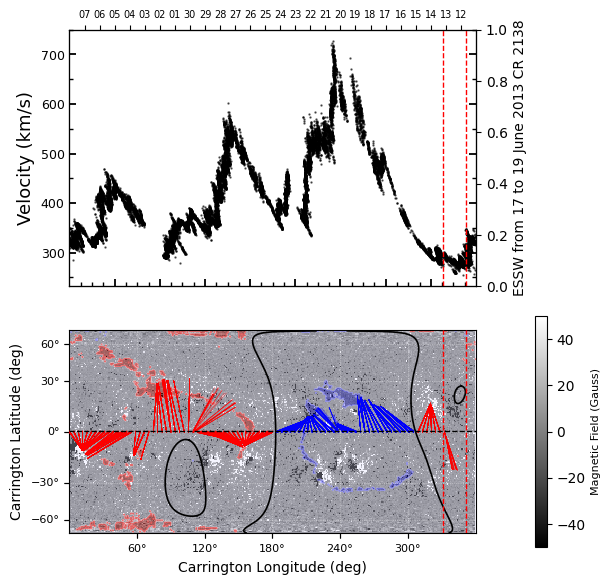

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import AutoMinorLocator, MaxNLocator
import astropy.units as u
import matplotlib.colors as mcolor
from astropy.coordinates import SkyCoord
from astropy.visualization.wcsaxes import formatter_locator

# === FIGURE 1: Velocity vs Footpoint Longitude ===
fig = plt.figure(figsize=(6, 6), constrained_layout=True)

# --- Upper panel ---
ax = fig.add_subplot(2, 1, 1)
ax.scatter(
    df_sel['footpoint_lon_deg'],
    df_sel['PROTON_BULK_SPEED_km/s'],
    color='k', alpha=0.6, s=0.5
)

ax.set_xticklabels([])
ax.set_ylabel('Velocity (km/s)', fontsize=13)

# Twin y-axis
ax_right = ax.twinx()
ax_right.set_ylabel("ESSW from 17 to 19 June 2013 CR 2138", fontsize=10)

# Tick formatting
ax.minorticks_on()
ax.yaxis.set_minor_locator(AutoMinorLocator(2))
ax.tick_params(axis='both', which='major', direction='in', length=5, width=1.3, labelsize=9)
ax.tick_params(axis='both', which='minor', direction='in', length=3, width=1)
ax.xaxis.set_ticks_position('bottom')
ax.yaxis.set_ticks_position('both')

# Vertical markers
plt.axvline(x=351, color='r', linestyle='--', lw=1)
plt.axvline(x=331, color='r', linestyle='--', lw=1)

# Limits
ax.xaxis.set_major_locator(MaxNLocator(10))
ax.set_xlim(
    min(df_sel['footpoint_lon_deg']),
    max(df_sel['footpoint_lon_deg'])
)

# Twin x-axis (dates)
ax_top = ax.twiny()
formatter = mdates.DateFormatter('%d')
ax_top.xaxis.set_major_locator(MaxNLocator(29))
ax_top.xaxis.set_major_formatter(formatter)

min_time = df_sel['EPOCH_yyyy-mm-ddThh:mm:ss.sssZ'].min()
max_time = df_sel['EPOCH_yyyy-mm-ddThh:mm:ss.sssZ'].max()
ax_top.set_xlim(max_time, min_time)
plt.setp(ax_top.get_xticklabels(), rotation=0, ha='center', fontsize=7)

# === FIGURE 2: PFSS / HMI Map ===
ax2 = fig.add_subplot(2, 1, 2, projection=hmi_map)

# Neutral line (HCS)
#if hasattr(pfss_out, 'source_surface_pils') and len(pfss_out.source_surface_pils) > 0:
#    ax2.plot_coord(pfss_out.source_surface_pils[0], color='k', linewidth=1)
if hasattr(pfss_out, 'source_surface_pils') and len(pfss_out.source_surface_pils) > 0:
    for pil in pfss_out.source_surface_pils:
        if pil is None or len(pil.lon) == 0:
            continue
        try:
            ax2.plot_coord(pil, color='k', linewidth=1.2)
        except Exception:
            continue

# HMI background
im = hmi_map.plot(axes=ax2, cmap='gray', norm=None, vmin=-50.0, vmax=50.0)

# Colorbar
cbar = fig.colorbar(im, pad=0.02, shrink=0.9, ax=ax2)
cbar.set_label('Magnetic Field (Gauss)', size=8)

# Topology overlay
ax2.contourf(topologies, cmap='bwr', norm=None, alpha=0.3)

# Polarity mapping
color_dict = {-1: 'blue', 0: 'black', 1: 'red'}

# Field lines
for fline in flines:
    coords = fline.coords
    if len(coords.lon) == 0 or len(coords.lat) == 0:
        continue

    lon_start = coords.lon[0].to(u.deg).value
    lat_start = coords.lat[0].to(u.deg).value
    lon_end   = coords.lon[-1].to(u.deg).value
    lat_end   = coords.lat[-1].to(u.deg).value

    polarity = getattr(fline, "polarity", 0)
    color = color_dict.get(polarity, 'black')

    # Avoid wrap-around
    if np.abs(lon_start - lon_end) < 200:
        try:
            ax2.plot_coord(
                SkyCoord(
                    [lon_start, lon_end],
                    [lat_start, lat_end],
                    unit='deg',
                    frame=hmi_map.coordinate_frame
                ),
                color=color,
                linewidth=0.3,   #thinner lines
                alpha=0.8
            )
        except Exception:
            continue

# Coordinate formatting
lon = ax2.coords[0]
lat = ax2.coords[1]

lon.set_ticks([0, 60, 120, 180, 240, 300, 360] * u.deg)
lon.set_ticklabel_position('b')
lon.set_ticklabel(size=8)
lon.set_axislabel("Carrington Longitude (deg)", fontsize=10)
lon.set_major_formatter('d')

lat.set_ticks([-90, -60, -30, 0, 30, 60, 90] * u.deg)
lat.set_ticklabel(size=8)
lat.set_axislabel("Carrington Latitude (deg)", fontsize=10)
lat.set_major_formatter('d')

# Markers
ax2.set_title("")
ax2.axvline(x=(351 * u.deg).value, color='red', linestyle='--', linewidth=1)
ax2.axvline(x=(331* u.deg).value, color='red', linestyle='--', linewidth=1)
ax2.axhline(y=90, color='black', linestyle='--', linewidth=1)

plt.show()